# Complex geometric phase from rotated multilayer contours · theory versus Maxwell

**Same checkpoint and physical structure as the revised optimization notebook.** The total height $H$ is fixed as the number of directly adjacent rotated layers $N$ changes. We solve (a) full periodic Maxwell stacks, (b) patterned supercells, and optionally (c) finite arrays with lateral PML.

This version **separates three distinct objects:**

1. A *finite-step Jones Wilson product* from equal-ambient isolated slices (a control, **not** a local $K$).
2. A candidate Wilson product from the forward polarization subspace extracted from the **two-way 4×4 transfer-generator proxy** of each matched thin slice. This is a model diagnostic, **not a certified Maxwell Bloch generator** (specular-only reduction omits evanescent channels).
3. The complete, coupled, multilayer electromagnetic scattering result, including reflection/resonances.

We explicitly monitor $\eta$, splitting, anisotropy, mode conditioning, orientation reversal, and $N$-convergence. The imaginary Wilson phase of orthogonal rotating states includes a **finite-step projection artifact** and is not evidence of a gain/loss holonomy. Resonant amplitudes add coherently, so there is no general exact additive phase decomposition.

## 1 · Load the transport-optimized checkpoint; configure independent experiments

The checkpoint must contain `transport` metadata specifying physical total height, background medium, and ports. For exploratory use of an old checkpoint, set `ALLOW_LEGACY_CHECKPOINT=True` explicitly and supply `H_OVERRIDE_UM`. Supercells and finite arrays are optional high-cost validation stages; an N-dependent Meep resolution guard prevents under-resolved few-nanometer layers.

In [ ]:
# Shared engines live in ../core (see ../PROJECTS.md). Run with the notebook folder as cwd.
import sys; from pathlib import Path
sys.path.insert(0, str((Path.cwd().parent / 'core').resolve()))

In [1]:
from pathlib import Path
from dataclasses import replace
import hashlib, json, time
import numpy as np
import matplotlib.pyplot as plt
import torch

from engine_contour_checkpoint import checkpoint_candidates, read_candidate
from engine_multilayer_characterization import (
    scattering_to_transfer, forward_generator_proxy,
    orthogonal_projection_baseline, jones_metrics_numpy, solve_rcwa,
    Pattern, RCWAOptions, FiniteOptions, rotation_angles, orientations,
    layer_masks, solve_stack, solve_local_slices, transport_analysis,
    loop_from_model, specular_metrics, projected_channel,
    one_pole_background, finite_prism_specs, finite_meep_forward,
)
from engine_rcwa import Settings as RCWASettings

# --- Experiment switches ---
CHECKPOINT = None              # Path('../03_contour_ep_transport/results/elliptical_contour_transmission_ep/contour_...npz')
ALLOW_ENGINE_MISMATCH = False # True only after intentionally reviewing code drift
ALLOW_LEGACY_CHECKPOINT = False # Legacy checkpoint lacks physical stack objective
RUN_WILSON_BENCHMARK = True
RUN_PERIODIC = True
RUN_SUPERCELL = False           # Periodic spatially varying 2x2/3x3 supercell
RUN_FINITE = False              # True 3D Meep + lateral PML (expensive)
RUN_RESONANCE = False           # Full RCWA wavelength sweep, fit a pole/background
RUN_CONVERGENCE = False         # Increase Fourier orders / spatial resolution
RUN_HEIGHT_SWEEP = False        # Change total H separately from N (adiabaticity)
RUN_FINITE_CONVERGENCE = False  # Optional second full 3D resolution
FORCE_RECOMPUTE = False

N_SWEEP = (6, 8, 12, 16, 20, 24) # N=4 has a singular orthogonal-projection control
DIRECTIONS = (+1, -1, 0)       # Forward, reversed, and no-rotation controls
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
PERIODIC_OPT = RCWAOptions(order=7, pixels_per_cell=96, device=DEVICE, precision='complex128')
SUPER = Pattern(nx=2, ny=2, qx=1, qy=0)
SUPER_OPT = RCWAOptions(order=5, pixels_per_cell=72, device=DEVICE, precision='complex128')
FINITE_OPT = FiniteOptions(nx=3, ny=3, resolution=160) # Needs ≥4 cells per physical layer
SUPER_N = (4, 8, 12)           # Use a manageable small supercell first
FINITE_N = (4, 8)              # Few expensive independent 3D samples
H_OVERRIDE_UM = None           # None = optimizer-defined total H
RUN_TRANSFER_GENERATOR = True   # Match-ambient two-way 4x4 local diagnostic
RUN_SPATIAL_FINITE = False      # Optional finite array with lateral winding
WAVELENGTH_OVERRIDE_UM = None  # None = saved wavelength; normally 0.633

OUT = Path('results/multilayer_geometric_phase')
OUT.mkdir(parents=True, exist_ok=True)
if CHECKPOINT is None:
    candidates = [f for f in checkpoint_candidates('ellipse', root='../03_contour_ep_transport/results')
                  if f.name.startswith('contour_transport_')]
    if not candidates and ALLOW_LEGACY_CHECKPOINT:
        candidates = checkpoint_candidates('ellipse', root='../03_contour_ep_transport/results')
    if not candidates:
        raise FileNotFoundError('No saved elliptical optimizer contour_*.npz. '
            'Run the optimizer first, or explicitly set CHECKPOINT.')
    CHECKPOINT = candidates[0]

saved = read_candidate(CHECKPOINT, expected_kind='ellipse',
    allow_engine_mismatch=ALLOW_ENGINE_MISMATCH)
geom, cfg, rules, raw = saved['geom'], saved['cfg'], saved['rules'], saved['raw']
physical_meta=saved['metadata'].get('transport')
if not physical_meta and not ALLOW_LEGACY_CHECKPOINT:
    raise ValueError('Requires full-stack transport-optimized checkpoint. Run revised optimizer.')
ContourDesign = geom.ContourDesign
model = ContourDesign(rules, raw, device=DEVICE, dtype=torch.float64)
with torch.no_grad():
    p = model.values()
    H = float(physical_meta['total_height_um'] if physical_meta else p['height'].detach().cpu()) if H_OVERRIDE_UM is None else float(H_OVERRIDE_UM)
    LAMBDA0 = float(cfg.wavelength) if WAVELENGTH_OVERRIDE_UM is None else float(WAVELENGTH_OVERRIDE_UM)
if H <= 0 or LAMBDA0 <= 0:
    raise ValueError('Total stack height and wavelength must be positive')
if float(cfg.n_fin_kappa) != 0.:
    raise ValueError("This characterization expects the optimizer's real-index material")

# Separate the cached RCWA results of different checkpoints and solver settings.
checkpoint_hash = hashlib.sha256(Path(CHECKPOINT).read_bytes()).hexdigest()[:16]
print('Checkpoint:', saved['path'])
print('Geometry engine:', geom.__file__)
print(f'Total H={H:.5f} µm, wavelength={LAMBDA0:.5f} µm, material n={cfg.n_fin}, device={DEVICE}')
print('N:', N_SWEEP, '| h=H/N; no interlayer spacers')
print('Supercell:', SUPER, '| finite array:', FINITE_OPT)
BACKGROUND_INDEX = (physical_meta['setup']['background_index'] if physical_meta else 1.0)
BOTTOM_INDEX = (physical_meta['setup']['bottom_index'] if physical_meta else cfg.n_sub)
TOP_INDEX = (physical_meta['setup']['top_index'] if physical_meta else 1.0)
print('Physical medium:',BACKGROUND_INDEX,'bottom:',BOTTOM_INDEX,'top:',TOP_INDEX)

Checkpoint: results/elliptical_contour_transmission_ep/contour_transport_7de41184180b129f.npz
Geometry engine: /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/engine_ellipse_contour.py
Total H=0.63300 µm, wavelength=0.63300 µm, material n=2.584, device=cuda
N: (6, 8, 12, 16, 20, 24) | h=H/N; no interlayer spacers
Supercell: Pattern(nx=2, ny=2, qx=1, qy=0) | finite array: FiniteOptions(nx=3, ny=3, resolution=160, pml_um=0.3, lateral_pad_um=0.35, z_pad_wavelengths=1.2, decay_after=120.0, pulse_width_freq=0.12, n_profile_points=256)
Physical medium: 1.0 bottom: 1.46 top: 1.0


## 2 · Preview the actual layer geometry and check 2π closure

`contour_fill()` is the **same mask code used by the optimizer**. In a 2×2 supercell, each site also has a transverse orientation offset. A full 2π rotation in the geometry parameter is used; an eigenvector winding might differ (e.g. an ellipse is π-periodic). Pixelated slices are physically adjacent and each has thickness `H/N`. The number of slices does not change the total device height.

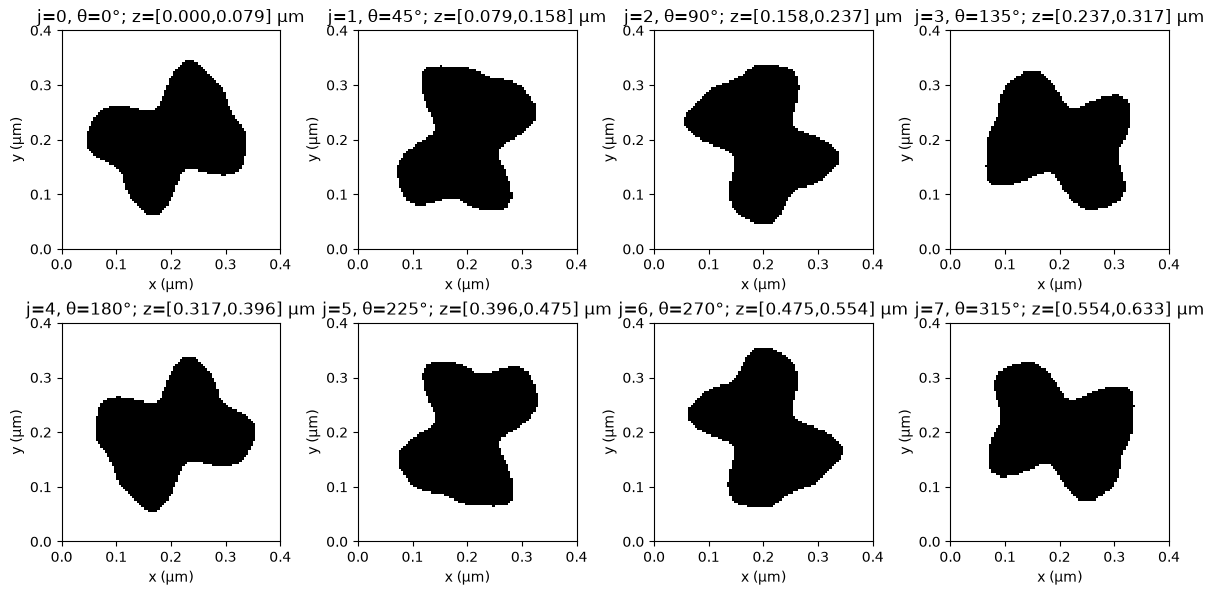

In [2]:
def gallery(N=8, pattern=Pattern(), opts=PERIODIC_OPT):
    with torch.no_grad():
        masks=layer_masks(p,rules,geom,N,pattern,pixels_per_cell=opts.pixels_per_cell)
    arr=masks.cpu().numpy()
    ncols=min(4,N);nrows=int(np.ceil(N/ncols))
    fig,axs=plt.subplots(nrows,ncols,figsize=(3*ncols,3*nrows),squeeze=False)
    for j,ax in enumerate(axs.flat):
        if j>=N:ax.axis('off');continue
        extent=[0,pattern.ny*cfg.period,0,pattern.nx*cfg.period]
        ax.imshow(arr[j].T,origin='lower',cmap='gray_r',interpolation='nearest',extent=extent)
        ax.set_aspect('equal');ax.set_title(f'j={j}, θ={360*j/N:.0f}°; z=[{H*j/N:.3f},{H*(j+1)/N:.3f}] µm')
        ax.set_xlabel('x (µm)');ax.set_ylabel('y (µm)')
    fig.tight_layout();plt.show()
    return arr

first_masks=gallery(N=8)
if RUN_SUPERCELL:
    super_preview=gallery(N=4, pattern=SUPER, opts=SUPER_OPT)

## 3 · Validate the Wilson implementation against the paper's analytical model

Jana & Genevet use the generator $K(\phi,\eta)=\begin{pmatrix}i\eta&e^{-i\phi}\\ e^{i\phi}&-i\eta\end{pmatrix}$ and derive $\gamma_\pm=\pi\pm i\pi\eta/\sqrt{1-\eta^2}$ for a continuous closed cycle. Numerically computing the Wilson loop for **this exact generator** is a useful no-Maxwell regression test. Branch labeling is continuous up to an arbitrary exchange of ±, and real phases are modulo $2\pi$. The notebook deliberately separates this analytic benchmark from the meta-atom's Jones eigenvectors.

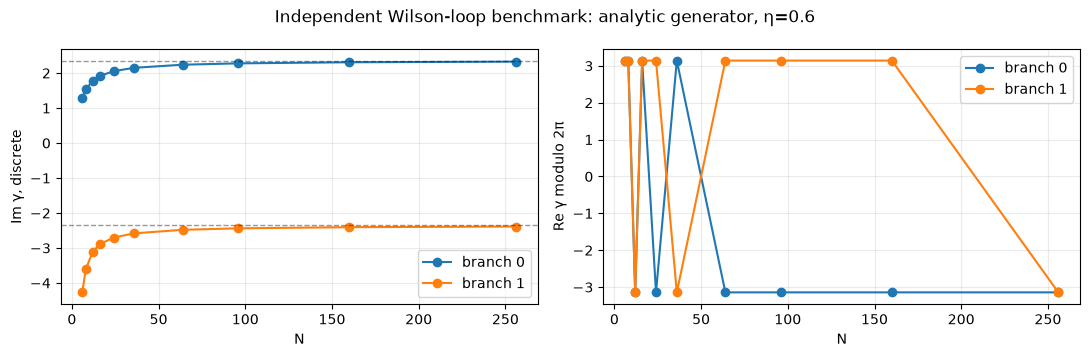

In [3]:
if RUN_WILSON_BENCHMARK:
    ETA_TEST=.6
    Ns=np.array([6,8,12,16,24,36,64,96,160,256])
    computed=[]
    for N in Ns:
        phis=rotation_angles(int(N))
        K=np.array([[[1j*ETA_TEST,np.exp(-1j*phi)],
                     [np.exp(1j*phi),-1j*ETA_TEST]] for phi in phis])
        w=transport_analysis(K)
        computed.append(w['gamma'])
    computed=np.asarray(computed)
    target=loop_from_model(256,ETA_TEST)
    fig,ax=plt.subplots(1,2,figsize=(11,3.6))
    for m in range(2):
        ax[0].plot(Ns,computed[:,m].imag,'o-',label=f'branch {m}')
        ax[0].axhline(target[m].imag,ls='--',lw=1,color='k',alpha=.4)
        ax[1].plot(Ns,np.angle(np.exp(1j*computed[:,m].real)),'o-',label=f'branch {m}')
    ax[0].set_ylabel('Im γ, discrete');ax[1].set_ylabel('Re γ modulo 2π')
    for a in ax:a.set_xlabel('N');a.grid(alpha=.25);a.legend()
    fig.suptitle('Independent Wilson-loop benchmark: analytic generator, η=0.6')
    plt.tight_layout();plt.show()
    assert abs(computed[-1,0].imag-target[0].imag)<.12
    assert abs(computed[-1,1].imag-target[1].imag)<.12

## 4 · Cached full-stack RCWA: rotation reversal and unrotated control

The `solve_stack()` path calls **one TORCWA `rcwa` model containing all N patterned layers**, not $T_N\dots T_1$. Light encounters internal interfaces and multiple scattering. Both full $4\times4$ zero-order scattering and the outgoing power summed over represented diffraction orders are stored. The zero-order 4×4 matrix alone is **not** unitary whenever supercell diffraction orders propagate. All port phases are referenced to device faces; the saved single-layer fixed monitor planes are not recycled incorrectly.

In [4]:
def cached_stack(N, direction, pattern=Pattern(), opts=PERIODIC_OPT,
                 wavelength=None, force=FORCE_RECOMPUTE):
    wavelength=float(wavelength or LAMBDA0)
    identity = dict(checkpoint_hash=checkpoint_hash, N=int(N), direction=int(direction),
        pattern=vars(pattern), opts=vars(opts), wavelength=wavelength, H=H,
        geom_signature=saved['metadata'].get('code',{}),
        background_index=BACKGROUND_INDEX,bottom_index=BOTTOM_INDEX,top_index=TOP_INDEX)
    key=hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()[:18]
    folder=OUT/'rcwa_cache';folder.mkdir(exist_ok=True)
    path=folder/f'stack_{key}.npz'
    if path.exists() and not force:
        with np.load(path,allow_pickle=False) as z:
            return dict(S=z['S'],T=z['S'][2:4,:2],
                 budget=None if z['budget'].size==0 else z['budget'],
                 total_power=None if z['budget'].size==0 else z['budget'].sum(1),
                 N=int(N),direction=int(direction),wavelength_um=wavelength)
    started=time.perf_counter()
    with torch.no_grad():
        result=solve_stack(p,rules,geom,cfg,N,pattern=pattern,opts=opts,
                 direction=direction,height_um=H,wavelength_um=wavelength,
                 bottom_index=BOTTOM_INDEX,top_index=TOP_INDEX,
                 background_index=BACKGROUND_INDEX)
    np.savez_compressed(path,S=result['S'],
            budget=np.array([]) if result['budget'] is None else result['budget'],
            configuration=json.dumps(identity,sort_keys=True))
    print(f'full RCWA N={N:2}, dir={direction:+d}, cell={pattern.nx}x{pattern.ny} '
          f'order={opts.order}: {time.perf_counter()-started:.1f}s, '
          f'T0={specular_metrics(result["S"])["T_forward"]:.4f}')
    return result

periodic={}
if RUN_PERIODIC:
    for N in N_SWEEP:
        for direction in DIRECTIONS:
            periodic[(N,direction)] = cached_stack(N,direction)
    print(f'Solved {len(periodic)} periodic full-wave stacks')

full RCWA N= 6, dir=+1, cell=1x1 order=7: 4.0s, T0=0.8250
full RCWA N= 6, dir=-1, cell=1x1 order=7: 3.7s, T0=0.8382
full RCWA N= 6, dir=+0, cell=1x1 order=7: 5.0s, T0=0.9339
full RCWA N= 8, dir=+1, cell=1x1 order=7: 8.7s, T0=0.7889
full RCWA N= 8, dir=-1, cell=1x1 order=7: 9.2s, T0=0.8088
full RCWA N= 8, dir=+0, cell=1x1 order=7: 12.0s, T0=0.9339
full RCWA N=12, dir=+1, cell=1x1 order=7: 17.5s, T0=0.7764
full RCWA N=12, dir=-1, cell=1x1 order=7: 17.6s, T0=0.8004
full RCWA N=12, dir=+0, cell=1x1 order=7: 17.3s, T0=0.9339
full RCWA N=16, dir=+1, cell=1x1 order=7: 24.8s, T0=0.7817
full RCWA N=16, dir=-1, cell=1x1 order=7: 24.8s, T0=0.8029
full RCWA N=16, dir=+0, cell=1x1 order=7: 25.0s, T0=0.9339
full RCWA N=20, dir=+1, cell=1x1 order=7: 32.0s, T0=0.7849
full RCWA N=20, dir=-1, cell=1x1 order=7: 31.5s, T0=0.8030
full RCWA N=20, dir=+0, cell=1x1 order=7: 33.1s, T0=0.9339
full RCWA N=24, dir=+1, cell=1x1 order=7: 39.8s, T0=0.7910
full RCWA N=24, dir=-1, cell=1x1 order=7: 41.3s, T0=0.8065
fu

## 5 · Local two-way transfer-generator **proxy** and Wilson-loop controls

The original calculation used eigenvectors of isolated **thin-slice transmission matrices**, which are not the local polarization generator of a contiguous stack. That Wilson product is now explicitly saved as an *isolated-Jones control*. For each slice we additionally compute its matched-ambient, two-sided complex S, convert to a specular 4×4 transfer matrix, and form $K_4=i\log(M)/h$. We retain only positive-directional-flux modes and project onto the two forward x/y amplitudes. **This is a controlled approximation**: singular transmission, strong evanescent coupling, logarithm branch ambiguity, or failure to identify two forward modes invalidates the local-generator inference. In that case we report a failure, not a complex geometric-phase detection.

Both bases are sampled at physical slice height $H/N$. A Wilson product requires consistent branch tracking and cyclic closure. The paper's analytic constant-$\eta$ formula applies only to its particular model, not automatically to this contour.

N= 6, dir=+1: isolated control η=0.0069, |Im γ|=[3.0604 3.0604], orthogonal projection Im γ=-4.1589; generator valid=True; 9.2s
N= 6, dir=-1: isolated control η=0.0069, |Im γ|=[2.5272 2.5272], orthogonal projection Im γ=-4.1589; generator valid=True; 11.1s
N= 8, dir=+1: isolated control η=0.0021, |Im γ|=[3.227 3.227], orthogonal projection Im γ=-2.7726; generator valid=True; 13.0s
N= 8, dir=-1: isolated control η=0.0021, |Im γ|=[3.227 3.227], orthogonal projection Im γ=-2.7726; generator valid=True; 12.2s
N=12, dir=+1: isolated control η=0.0004, |Im γ|=[1.9548 1.9548], orthogonal projection Im γ=-1.7261; generator valid=True; 17.8s
N=12, dir=-1: isolated control η=0.0004, |Im γ|=[1.9548 1.9548], orthogonal projection Im γ=-1.7261; generator valid=True; 21.3s
N=16, dir=+1: isolated control η=0.0001, |Im γ|=[1.4116 1.4116], orthogonal projection Im γ=-1.2668; generator valid=True; 24.1s
N=16, dir=-1: isolated control η=0.0001, |Im γ|=[1.4116 1.4116], orthogonal projection Im γ=-1.2668; g

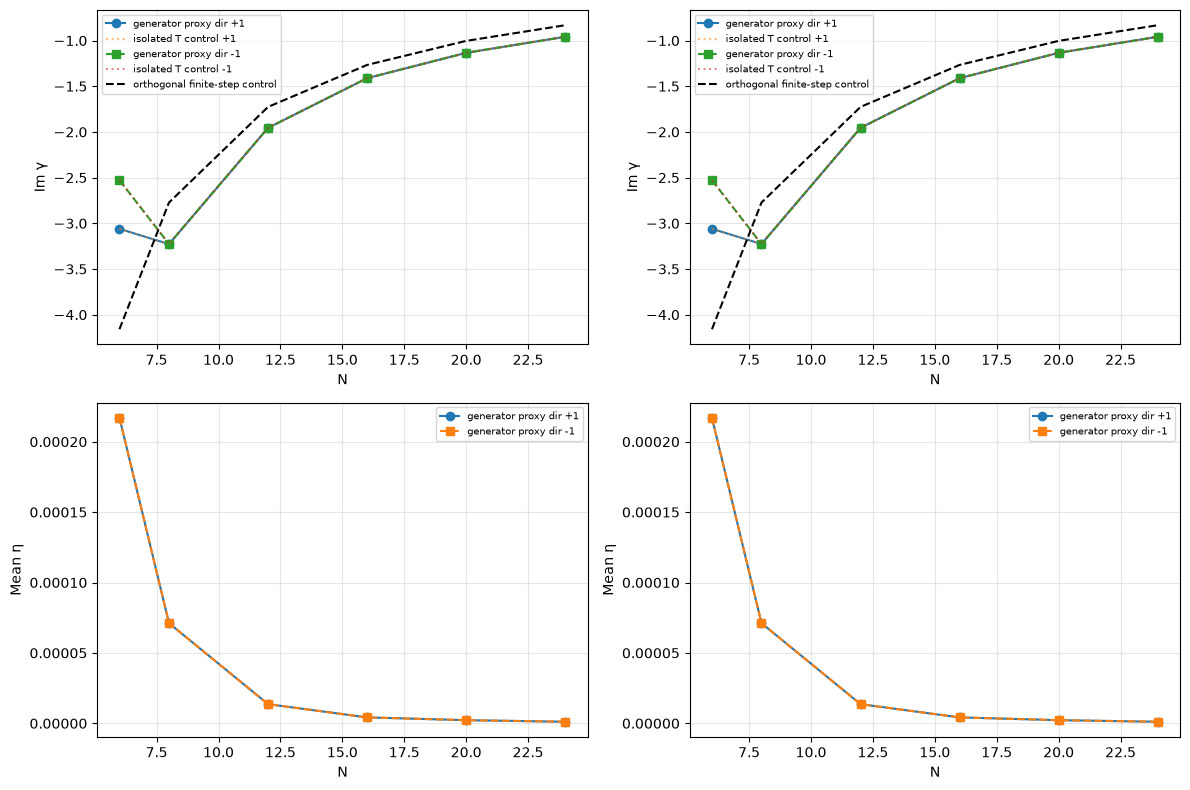

In [5]:
transport={}
slice_controls={}
generator_failures={}
generator_proxies={}
if RUN_PERIODIC:
    local_opts=replace(PERIODIC_OPT,diffraction_budget=False)
    for N in N_SWEEP:
        for direction in (+1,-1):
            started=time.perf_counter()
            with torch.no_grad():
                masks=layer_masks(p,rules,geom,N,Pattern(),direction=direction,
                                  pixels_per_cell=local_opts.pixels_per_cell)
                slices=[]
                for j in range(N):
                    result=solve_rcwa(masks[j:j+1],cfg,Pattern(),local_opts,
                        height_um=H/N,wavelength_um=LAMBDA0,
                        bottom_index=BACKGROUND_INDEX,top_index=BACKGROUND_INDEX,
                        background_index=BACKGROUND_INDEX)
                    slices.append(result['S'])
            slices=np.asarray(slices)
            control=transport_analysis(slices[:,2:4,:2],slice_height_um=H/N)
            slice_controls[(N,direction)]=control
            if RUN_TRANSFER_GENERATOR:
                try:
                    local=[forward_generator_proxy(S,H/N) for S in slices]
                    # Reconstruct matched two-mode propagation proxy from K4.
                    # This retains forward eigenvectors, not isolated T eigenvectors.
                    from scipy.linalg import expm
                    local_transfers=np.asarray([expm(-1j*rec['local_J']*H/N) for rec in local])
                    t=transport_analysis(local_transfers,slice_height_um=H/N)
                    generator_proxies[(N,direction)]=local
                    t['basis_source']='projected_forward_4x4_transfer_generator_proxy'
                    transport[(N,direction)]=t
                except (ValueError,np.linalg.LinAlgError) as exc:
                    generator_failures[(N,direction)]=str(exc)
                    print(f'Local generator INVALID N={N} d={direction:+d}:',exc)
            print(f'N={N:2}, dir={direction:+d}: isolated control η='
                  f'{control["eta"].mean():.4f}, |Im γ|='
                  f'{np.round(abs(control["gamma"].imag),4)}, '
                  f'orthogonal projection Im γ='f'{orthogonal_projection_baseline(N):.4f}; '
                  f'generator valid={(N,direction) in transport}; '
                  f'{time.perf_counter()-started:.1f}s')
    fig,axs=plt.subplots(2,2,figsize=(12,8))
    for direction,style in [(+1,'o-'),(-1,'s--')]:
        x=[N for N in N_SWEEP if (N,direction) in transport]
        for branch in (0,1):
            axs[0,branch].plot(x,[transport[(n,direction)]['gamma'][branch].imag for n in x],
                               style,label=f'generator proxy dir {direction:+d}')
            axs[0,branch].plot(N_SWEEP,
                [slice_controls[(n,direction)]['gamma'][branch].imag for n in N_SWEEP],
                ':',alpha=.55,label=f'isolated T control {direction:+d}')
            axs[1,branch].plot(x,[transport[(n,direction)]['eta'].mean() for n in x],
                               style,label=f'generator proxy dir {direction:+d}')
    for ax in axs[0]:
        ax.plot(N_SWEEP,[orthogonal_projection_baseline(n) for n in N_SWEEP],
                'k--',label='orthogonal finite-step control')
        ax.set(ylabel='Im γ',xlabel='N');ax.legend(fontsize=7);ax.grid(alpha=.3)
    for ax in axs[1]:
        ax.set(ylabel='Mean η',xlabel='N');ax.legend(fontsize=7);ax.grid(alpha=.3)
    plt.tight_layout();plt.show()
    if generator_failures:
        print('INVALID LOCAL-GENERATOR CASES (do not claim geometric holonomy):',generator_failures)

### 5a · Right and dual-left Poincaré trajectories of the **generator proxy**

Only display if a two-forward-mode generator projection was available. The isolated Jones controls are not presented as physical local modes.

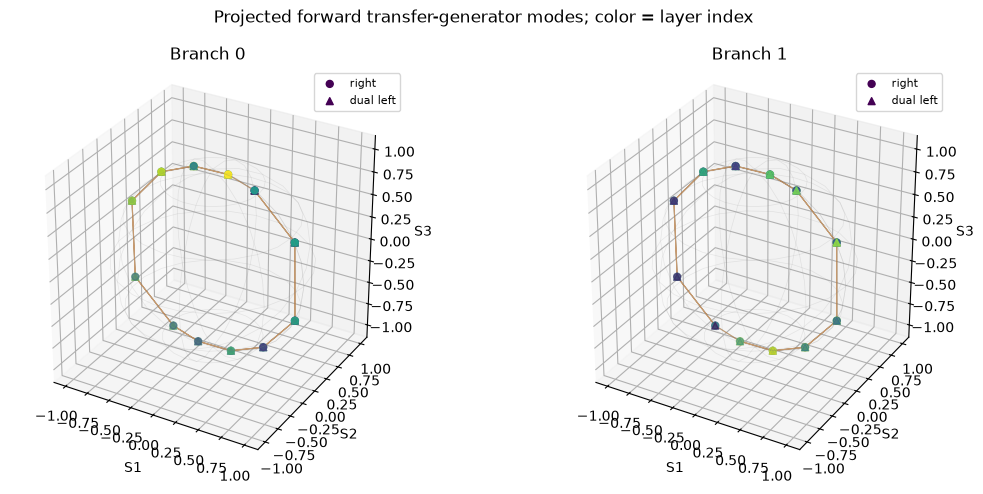

Dual-left / opposite-right Poincaré antipodality error: 2.220446049250313e-16


In [6]:
def stokes_vec(ket):
    a,b=np.asarray(ket,complex)
    normalization=np.vdot(ket,ket).real
    return np.array([2*np.real(np.conj(a)*b),
                     2*np.imag(np.conj(a)*b),
                     (abs(a)**2-abs(b)**2)])/normalization

if RUN_PERIODIC and transport:
    plot_N=max(n for n,d in transport if d==+1)
    t=transport[(plot_N,+1)]
    fig=plt.figure(figsize=(11,5))
    uv=np.linspace(0,2*np.pi,24);vv=np.linspace(0,np.pi,13)
    for branch in (0,1):
        ax=fig.add_subplot(1,2,branch+1,projection='3d')
        ax.plot_wireframe(np.outer(np.cos(uv),np.sin(vv)),
                          np.outer(np.sin(uv),np.sin(vv)),
                          np.outer(np.ones_like(uv),np.cos(vv)),
                          rstride=3,cstride=2,color='gray',alpha=.15,lw=.5)
        right=np.array([stokes_vec(v[:,branch]) for v in t['R']])
        left=np.array([stokes_vec(v[branch,:].conj()) for v in t['L']])
        for arr,label,marker in [(right,'right','o'),(left,'dual left','^')]:
            ax.plot(*arr.T,alpha=.5,lw=.8)
            ax.scatter(*arr.T,c=np.arange(len(arr)),cmap='viridis',s=25,marker=marker,label=label)
        ax.set(xlabel='S1',ylabel='S2',zlabel='S3',title=f'Branch {branch}')
        ax.set_box_aspect([1,1,1]);ax.legend(fontsize=8)
    fig.suptitle('Projected forward transfer-generator modes; color = layer index')
    plt.tight_layout();plt.show()
    # Biorthogonality: normalized left + is antipodal to right -.
    example_left=stokes_vec(t['L'][0,0,:].conj())
    example_opp=stokes_vec(t['R'][0,:,1])
    print('Dual-left / opposite-right Poincaré antipodality error:',
          np.linalg.norm(example_left+example_opp))

## 6 · Maxwell stack versus candidate Wilson/dynamical factorization

Only calculate the forward-eigenmode propagation proxy if the 4×4 transfer-based generator extraction succeeded. If it failed, show full-wave results and the failure diagnostic without substituting the isolated-Jones Wilson loop. Matching oriented and reversed stacks is a *signature*, not an exact three-way phase subtraction.

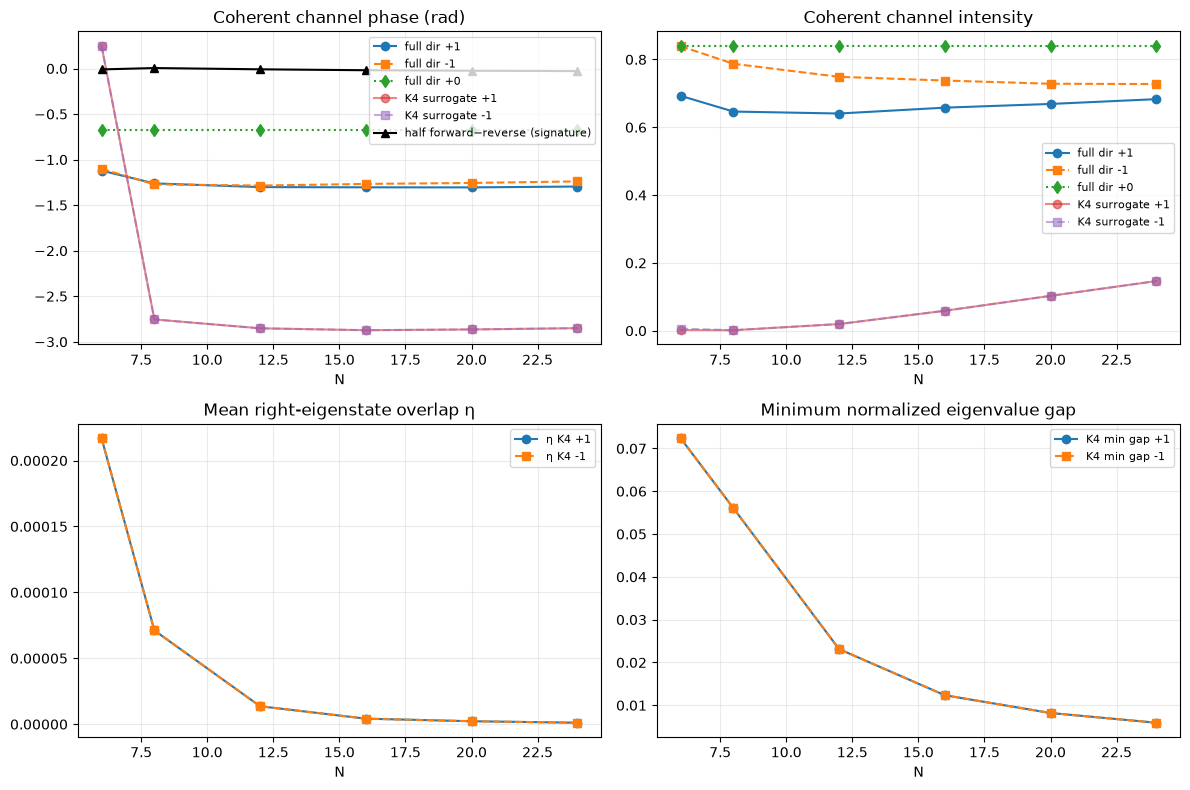

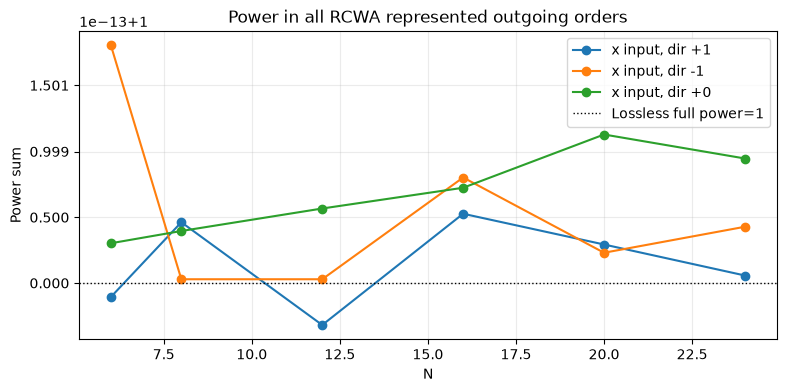

In [7]:
INPUT = np.array([1.,0.],complex)        # x-polarized illumination
ANALYZER = np.array([1.,0.],complex)     # x-polarized analyzer

def predicted_forward_jones(t):
    R0=t['R'][0];L0=t['L'][0]
    return R0 @ np.diag(t['eigenvalue_product'] *
                         t['forward_projection_product']) @ L0

if RUN_PERIODIC:
    fig,ax=plt.subplots(2,2,figsize=(12,8))
    for direction,style in [(1,'o-'),(-1,'s--'),(0,'d:')]:
        ch=[projected_channel(periodic[(n,direction)]['T'],INPUT,ANALYZER)
            for n in N_SWEEP]
        ax[0,0].plot(N_SWEEP,np.unwrap(np.angle(ch)),style,label=f'full dir {direction:+d}')
        ax[0,1].plot(N_SWEEP,np.abs(ch)**2,style,label=f'full dir {direction:+d}')
    for direction,style in [(1,'o-'),(-1,'s--')]:
        valid=[n for n in N_SWEEP if (n,direction) in transport]
        if not valid:
            print('No certified forward generator basis at direction',direction)
            continue
        pred=[projected_channel(predicted_forward_jones(transport[(n,direction)]),
                  INPUT,ANALYZER) for n in valid]
        ax[0,0].plot(valid,np.unwrap(np.angle(pred)),style,alpha=.55,
                    label=f'K4 surrogate {direction:+d}')
        ax[0,1].plot(valid,np.abs(pred)**2,style,alpha=.55,
                    label=f'K4 surrogate {direction:+d}')
        ax[1,0].plot(valid,[transport[(n,direction)]['eta'].mean() for n in valid],
                     style,label=f'η K4 {direction:+d}')
        ax[1,1].plot(valid,[transport[(n,direction)]['normalized_gap'].min() for n in valid],
                     style,label=f'K4 min gap {direction:+d}')
    odd=[.5*np.angle(projected_channel(periodic[(n,1)]['T'],INPUT,ANALYZER) /
                projected_channel(periodic[(n,-1)]['T'],INPUT,ANALYZER)) for n in N_SWEEP]
    ax[0,0].plot(N_SWEEP,np.unwrap(odd),'k^-',label='half forward−reverse (signature)')
    titles=('Coherent channel phase (rad)','Coherent channel intensity',
            'Mean right-eigenstate overlap η','Minimum normalized eigenvalue gap')
    for a,title in zip(ax.flat,titles):a.set_title(title);a.set_xlabel('N');a.grid(alpha=.25);a.legend(fontsize=8)
    plt.tight_layout();plt.show()

    # Measured order-resolved energy budget, not zero-order-only norm.
    fig,ax=plt.subplots(figsize=(9,4))
    for direction in DIRECTIONS:
        power=[periodic[(n,direction)]['total_power'][0] for n in N_SWEEP]
        ax.plot(N_SWEEP,power,'o-',label=f'x input, dir {direction:+d}')
    ax.axhline(1,color='k',ls=':',lw=1,label='Lossless full power=1')
    ax.set(title='Power in all RCWA represented outgoing orders',xlabel='N',ylabel='Power sum')
    ax.grid(alpha=.25);ax.legend();plt.show()

### 6a · Empty-stack propagation/reference phase and modal eigenvalue phase

Compute the complete **substrate–empty-stack–air** response with the **same total distance H and face-port convention**, and compare a selected coherent channel with the patterned stack. This is a well-defined reference observable, unlike an assumed unique "dynamical phase". A physical dynamical phase $-\int \operatorname{Re}\lambda_n dz$ would require a separately calibrated local generator; the isolated thin-slice transmission eigenvalue phases include interfaces and resonance. Consequently **neither** a bare reference subtraction **nor** the eigenvalue-product phase is by itself an exact separation of propagation and resonance.

Empty-stack channel amplitude: (0.9823614612678514-1.96472245319452e-09j)
Vacuum propagation phase k0*H: 6.283185307179586 rad (mod 2π)


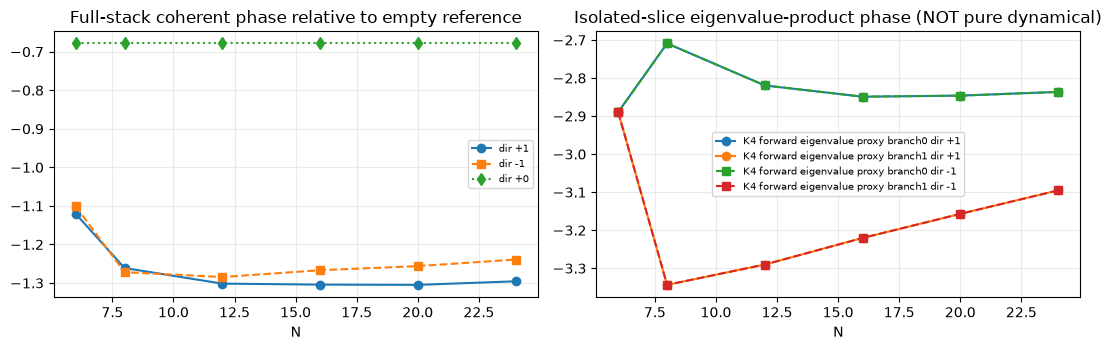

In [8]:
bare=None
if RUN_PERIODIC:
    from engine_multilayer_characterization import solve_rcwa
    with torch.no_grad():
        empty_mask=torch.zeros((1,PERIODIC_OPT.pixels_per_cell,PERIODIC_OPT.pixels_per_cell),
                               device=DEVICE,dtype=torch.float64)
        bare=solve_rcwa(empty_mask,cfg,Pattern(),PERIODIC_OPT,height_um=H,
                        wavelength_um=LAMBDA0)
    a_bare=projected_channel(bare['T'],INPUT,ANALYZER)
    if abs(a_bare)<1e-12:
        raise RuntimeError('Empty-stack analyzer channel is dark; choose another channel')
    print('Empty-stack channel amplitude:',a_bare)
    print('Vacuum propagation phase k0*H:',2*np.pi*H/LAMBDA0,'rad (mod 2π)')
    fig,ax=plt.subplots(1,2,figsize=(11,3.6))
    for direction,style in [(1,'o-'),(-1,'s--'),(0,'d:')]:
        relative=[projected_channel(periodic[(n,direction)]['T'],INPUT,ANALYZER)/a_bare
                  for n in N_SWEEP]
        ax[0].plot(N_SWEEP,np.unwrap(np.angle(relative)),style,label=f'dir {direction:+d}')
    for direction,style in [(1,'o-'),(-1,'s--')]:
        valid=[n for n in N_SWEEP if (n,direction) in transport]
        for branch in range(2):
            proxy=[transport[(n,direction)]['eigenvalue_phase'][branch] for n in valid]
            if valid:
                ax[1].plot(valid,np.unwrap(proxy),style,
                    label=f'K4 forward eigenvalue proxy branch{branch} dir {direction:+d}')
    ax[0].set_title('Full-stack coherent phase relative to empty reference')
    ax[1].set_title('Isolated-slice eigenvalue-product phase (NOT pure dynamical)')
    for a in ax:a.set_xlabel('N');a.grid(alpha=.25);a.legend(fontsize=7)
    plt.tight_layout();plt.show()

## 7 · Spatially varying arrays: a *periodic supercell* with several different orientations

For site `(a,b)`, define $\theta_{j,a,b} = 2\pi j/N+2\pi(q_x a/n_x+q_y b/n_y)$. The whole supercell repeats in x and y; this captures an infinite pattern with **spatially varying elements**, not an isolated finite array. The lateral simulation period becomes `(nx*period, ny*period)`, and multiple propagating orders can emerge. Track **total diffracted power** as well as the specular 4×4 matrix. Fourier order must be increased with supercell dimensions; low order is only a smoke test.

In [9]:
supercells={}
if RUN_SUPERCELL:
    assert SUPER.nx*SUPER.ny>1
    if SUPER_OPT.order < max(SUPER.nx,SUPER.ny)*PERIODIC_OPT.order:
        print('WARNING: supercell may need a larger Fourier order for convergence.')
    for N in SUPER_N:
        for direction in DIRECTIONS:
            supercells[(N,direction)] = cached_stack(N,direction,pattern=SUPER,opts=SUPER_OPT)
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    for direction in DIRECTIONS:
        spec=[specular_metrics(supercells[(N,direction)]['S'])['T_forward'] for N in SUPER_N]
        total=[supercells[(N,direction)]['total_power'][0] for N in SUPER_N]
        axs[0].plot(SUPER_N,spec,'o-',label=f'dir {direction:+d}')
        axs[1].plot(SUPER_N,total,'o-',label=f'dir {direction:+d}')
    axs[0].set_title('Zero-order transmission power; per x/y averaged')
    axs[1].set_title('All represented orders; bottom-x incidence')
    axs[1].axhline(1,color='k',ls=':',lw=1)
    for a in axs:a.set_xlabel('N');a.grid(alpha=.25);a.legend()
    plt.tight_layout();plt.show()

### 7a · Optional site-resolved Wilson phase across the spatial supercell

Each lattice site has a different orientation offset. Independently solving its isolated thin-slice trajectory is a **site-local Jones diagnostic**, not a substitute for the collective supercell Maxwell eigenmodes. We can map $\eta$ and $\mathrm{Im}\,\gamma$ across the array to see what portion of the analytic transport structure persists under spatial offsets.

In [10]:
site_wilson={}
if RUN_SUPERCELL:
    opts=replace(PERIODIC_OPT,diffraction_budget=False)
    N_SITE=SUPER_N[0]
    for a in range(SUPER.nx):
        for b in range(SUPER.ny):
            offset=2*np.pi*(SUPER.qx*a/SUPER.nx+SUPER.qy*b/SUPER.ny)
            site_p=dict(p,orientation=p['orientation']+offset)
            with torch.no_grad():
                Tsite=solve_local_slices(site_p,rules,geom,cfg,N_SITE,opts=opts,
                           height_um=H, direction=1)
            site_wilson[(a,b)]=transport_analysis(Tsite,slice_height_um=H/N_SITE)
    eta_grid=np.array([[site_wilson[(a,b)]['eta'].mean()
                      for b in range(SUPER.ny)] for a in range(SUPER.nx)])
    gamma_grid=np.array([[site_wilson[(a,b)]['gamma'][0].imag
                      for b in range(SUPER.ny)] for a in range(SUPER.nx)])
    fig,axs=plt.subplots(1,2,figsize=(9,3.8))
    for ax,arr,title in zip(axs,[eta_grid,gamma_grid],
            ['Local η (no neighbor coupling)','Local Im γ (Jones Wilson)']):
        im=ax.imshow(arr.T,origin='lower',cmap='viridis')
        ax.set(title=title,xlabel='Cell a',ylabel='Cell b');fig.colorbar(im,ax=ax)
    plt.tight_layout();plt.show()

## 8 · True finite arrays: optional independent 3D Meep with lateral PML

The finite case cannot be represented by **one** single-period RCWA cell. This section builds N×(nx×ny) polygonal prisms and runs a 3D Meep domain with X/Y/Z PML, an aperture illumination, and a substrate. It returns a forward **aperture-projected relative Jones matrix**, calibrated against the **bare substrate–air** baseline; it is *not* a full 4×4 S matrix or total radiated-power measurement. It also retains a reflection monitor and optional complex field maps. This is much more computationally expensive than periodic TORCWA, and the flux/collection aperture and spatial resolution require convergence studies.

`RUN_FINITE=False` is intentional: Meep may not be installed alongside CUDA TORCWA. If enabled, it calls the actual 3D Maxwell solver; no effective-medium substitute is silently used.

In [11]:
finite={}
if RUN_FINITE:
    for N in FINITE_N:
        for direction in (+1,-1,0):
            started=time.perf_counter()
            result=finite_meep_forward(p,rules,geom,cfg,N,
                opts=FINITE_OPT,height_um=H,wavelength_um=LAMBDA0,
                direction=direction,save_fields=(N==FINITE_N[0] and direction==1))
            finite[(N,direction)]=result
            print(f'Finite 3D {FINITE_OPT.nx}×{FINITE_OPT.ny}; N={N}, dir={direction}: '
                  f'{time.perf_counter()-started:.1f}s, '
                  f'x→x relative field={result["T_relative_bare"][0,0]:.3g}')
    fig,ax=plt.subplots(1,2,figsize=(11,3.8))
    for direction in (+1,-1,0):
        c=np.array([finite[(n,direction)]['T_relative_bare'][0,0] for n in FINITE_N])
        ax[0].plot(FINITE_N,np.unwrap(np.angle(c)),'o-',label=f'dir {direction:+d}')
        ax[1].plot(FINITE_N,np.abs(c)**2,'o-',label=f'dir {direction:+d}')
    for a,lab in zip(ax,['Phase relative to bare interface','Collected x→x intensity (relative)']):
        a.set_title(lab);a.set_xlabel('N');a.grid(alpha=.25);a.legend()
    plt.tight_layout();plt.show()

## 9 · Frequency sweep and phenomenological resonance/background decomposition

The physical response is $t(\omega)=t_{\mathrm{bg}}(\omega)+t_{\mathrm{res}}(\omega)$. We fit a single complex pole and linear background to a **real-frequency** projected-channel sweep. This is an *empirical Fano model*; its pole is not a certified quasinormal-mode pole and its decomposition is nonunique. In particular, `angle(total)` is generally **not** `angle(bg)+angle(res)`. A true resonant-mode analysis would require complex-frequency continuation and/or QNM boundary-value solves.

Separately, the homogeneous/bare-interface control gives a referenced total propagation baseline, not a unique geometric/dynamical decomposition. Plotting residuals and resonance stability is mandatory before interpreting the fit.

In [12]:
SPECTRAL_N = 8
SPECTRAL_DIRECTION = +1
WAVELENGTHS_UM = np.linspace(LAMBDA0*.94,LAMBDA0*1.06,21)
resonance_fit=None
if RUN_RESONANCE:
    if len(WAVELENGTHS_UM)<9:raise ValueError('Need >=9 points for pole/background fit')
    # Fit expects increasing frequency, not increasing wavelength.
    wavs=WAVELENGTHS_UM[::-1]
    freqs=1/wavs
    records=[]
    for lam in wavs:
        rr=cached_stack(SPECTRAL_N,SPECTRAL_DIRECTION, wavelength=lam)
        records.append(projected_channel(rr['T'],INPUT,ANALYZER))
    resonance_fit=one_pole_background(freqs,np.asarray(records))
    print('Empirical pole frequency (1/µm):',resonance_fit['complex_pole_um'])
    print('Relative fit residual:',resonance_fit['residual_relative'])
    fig,axs=plt.subplots(2,2,figsize=(12,8))
    for z,label in [('observed','full RCWA'),('fitted','sum of fit'),
                    ('background','background'),('resonant','resonant term')]:
        val=resonance_fit[z]
        axs[0,0].plot(wavs,val.real,'o-' if label=='full RCWA' else '-',label=label)
        axs[0,1].plot(wavs,val.imag,'o-' if label=='full RCWA' else '-',label=label)
        axs[1,0].plot(wavs,np.abs(val)**2,'o-' if label=='full RCWA' else '-',label=label)
        axs[1,1].plot(wavs,np.unwrap(np.angle(val)),'o-' if label=='full RCWA' else '-',label=label)
    for a,title in zip(axs.flat,['Real(t)','Imag(t)','|t|²','Unwrapped arg(t)']):
        a.set(title=title,xlabel='Wavelength (µm)');a.grid(alpha=.25);a.legend(fontsize=7)
    plt.tight_layout();plt.show()

## 10 · Fourier-order / spatial-resolution convergence and controls

First converge the full complex 4×4 scattering matrix and all-order power at a few representative N. For a supercell, the Fourier order usually must grow with its larger physical periodicity. An additional `H` sweep (with N fixed) tests *adiabaticity* separately from discretization: with fixed H, $d\theta/dz=2\pi/H$ does **not** decrease as N increases. Finite-array FDTD needs its own resolution and aperture-convergence checks.

In [13]:
convergence=[]
if RUN_CONVERGENCE:
    N_TEST=8
    orders=(3,4,5)
    previous=None
    for order in orders:
        opts=replace(PERIODIC_OPT,order=order,pixels_per_cell=144)
        S=cached_stack(N_TEST,1,opts=opts)['S']
        delta=np.nan if previous is None else np.linalg.norm(S-previous)/max(np.linalg.norm(S),1e-15)
        convergence.append((order,delta))
        print('Fourier order:',order,'full-S relative change:',delta)
        previous=S
    # Optional adiabatic/thickness study: different physical devices.
    # H_OVERRIDE_UM above controls the global geometry; rerun with larger H
    # and preserve the checkpoint identity in the cache key.

### 10a · Explicit thickness sweep at fixed N (adiabaticity)

Holding total $H$ fixed while increasing $N$ only refines the rotation discretization: $d\theta/dz=2\pi/H$ remains unchanged. This **independent** control changes H while keeping N fixed. It tests whether larger H leads toward the adiabatic Wilson prediction (provided the contour supports distinguishable modes). None of these values override the saved optimized height in the main run.

In [14]:
height_results={}
if RUN_HEIGHT_SWEEP:
    N_HEIGHT=12
    height_values=[H,2*H,4*H]
    for hh in height_values:
        with torch.no_grad():
            local_opts=replace(PERIODIC_OPT,diffraction_budget=False)
            masks=layer_masks(p,rules,geom,N_HEIGHT,Pattern(),direction=1,
                pixels_per_cell=local_opts.pixels_per_cell)
            slices=[solve_rcwa(masks[j:j+1],cfg,Pattern(),local_opts,
                height_um=hh/N_HEIGHT,bottom_index=BACKGROUND_INDEX,
                top_index=BACKGROUND_INDEX,background_index=BACKGROUND_INDEX)['S']
                for j in range(N_HEIGHT)]
            from scipy.linalg import expm
            forward=[forward_generator_proxy(S,hh/N_HEIGHT) for S in slices]
            modeled=np.array([expm(-1j*z['local_J']*hh/N_HEIGHT) for z in forward])
            theo=transport_analysis(modeled,slice_height_um=hh/N_HEIGHT)
            physical=solve_stack(p,rules,geom,cfg,N_HEIGHT,opts=PERIODIC_OPT,
                       height_um=hh,direction=1,bottom_index=BOTTOM_INDEX,
                       top_index=TOP_INDEX,background_index=BACKGROUND_INDEX)
        height_results[hh]=dict(transport=theo,full=physical)
        print(f'H={hh:.3f} µm: Im γ={np.round(theo["gamma"].imag,3)}, '
              f'full specular T={specular_metrics(physical["S"])["T_forward"]:.3f}')
    fig,ax=plt.subplots(1,2,figsize=(10,4))
    for b in (0,1):
        ax[0].plot(height_values,[height_results[h]['transport']['gamma'][b].imag
                for h in height_values],'o-',label=f'Wilson branch {b}')
    ax[1].plot(height_values,[np.angle(projected_channel(
            height_results[h]['full']['T'],INPUT,ANALYZER)) for h in height_values],'o-')
    ax[0].set(title='Im Wilson phase (K4 forward-subspace PROXY)',xlabel='Total H (µm)')
    ax[1].set(title='Measured channel phase (full RCWA)',xlabel='Total H (µm)')
    for a in ax:a.grid(alpha=.25)
    ax[0].legend();plt.tight_layout();plt.show()

### 10b · Optional finite-array PML-grid convergence

Meep 3D does not use the RCWA Fourier-order convergence criterion. Rerun one selected finite array at two spatial resolutions, keeping **physical aperture, PML width, propagation monitors, and geometry** unchanged. The complex projected Jones matrix should converge before any phase result is interpreted.

In [15]:
finite_convergence={}
if RUN_FINITE_CONVERGENCE:
    N_TEST=FINITE_N[0]
    for resolution in (FINITE_OPT.resolution, int(FINITE_OPT.resolution*1.5)):
        o=replace(FINITE_OPT,resolution=resolution)
        finite_convergence[resolution]=finite_meep_forward(p,rules,geom,cfg,N_TEST,
             opts=o,height_um=H,wavelength_um=LAMBDA0,direction=1)
    r0,r1=sorted(finite_convergence)
    T0=finite_convergence[r0]['T_relative_bare']
    T1=finite_convergence[r1]['T_relative_bare']
    print('Finite complex-Jones relative difference:',
          np.linalg.norm(T1-T0)/max(np.linalg.norm(T1),1e-12))


## 11 · Research summary, numerical caveats, and saved complex data

**Interpretation boundary**: We can isolate the geometric Wilson holonomy of our **chosen sequence of local Jones eigenspaces**. We cannot uniquely split the actual full-wave phase into exactly three independent scalars (geometric + dynamical + resonance) without additional effective-generator assumptions. The physical comparison is strongest when we demonstrate invariance/reversal under winding direction while keeping spectra and integrated propagation matched, and show convergence versus N, H, RCWA order, and source collection geometry.

Files include the raw complex 4×4 RCWA matrices, all-order power budgets, both eigenvector bases and Wilson products, resonance fit if enabled, and finite-array field records if enabled. They are never replaced by amplitude-only summaries.

In [16]:
payload={'checkpoint':str(CHECKPOINT),'checkpoint_sha256_16':checkpoint_hash,
         'N_sweep':list(map(int,N_SWEEP)),'height_um':H,'wavelength_um':LAMBDA0,
         'n_fin':float(cfg.n_fin),'model_kind':saved['kind'],
         'periodic_options':vars(PERIODIC_OPT), 'supercell_options':vars(SUPER_OPT),
         'pattern':vars(SUPER),'finite_options':vars(FINITE_OPT),
         'embedding':dict(background=BACKGROUND_INDEX,bottom=BOTTOM_INDEX,top=TOP_INDEX),
         'generator_failures':{str(k):v for k,v in generator_failures.items()},
         'caveats':['Isolated-Jones Wilson is a CONTROL, not the local propagation generator',
                    'Projected two-way K4 is a model proxy; lacks evanescent interlayer channels',
                    'Unrotated/reversed odd phase is a signature, not exact separation',
                    'Fano fit is phenomenological; resonant and background amplitudes add',
                    'Finite Meep matrices are aperture-projected relative transmission']}
(OUT/'multilayer_run_manifest.json').write_text(json.dumps(payload,indent=2,default=str))

if periodic:
    keys=sorted(periodic)
    np.savez_compressed(OUT/'periodic_full_wave.npz',
        index=np.asarray(keys,int),S=np.asarray([periodic[k]['S'] for k in keys]),
        budgets=np.asarray([periodic[k]['budget'] for k in keys]),
        checkpoint_hash=checkpoint_hash, H=H, wavelength=LAMBDA0)
if transport:
    keys=sorted(transport)
    np.savez_compressed(OUT/'local_wilson_transport.npz',
        index=np.asarray(keys,int),
        gamma=np.asarray([transport[k]['gamma'] for k in keys]),
        W=np.asarray([transport[k]['W'] for k in keys]),
        forward_product=np.asarray([transport[k]['forward_projection_product'] for k in keys]),
        eta=np.array([transport[k]['eta'] for k in keys],dtype=object) if False else
            np.array([np.mean(transport[k]['eta']) for k in keys]),
        eigen_products=np.array([transport[k]['eigenvalue_product'] for k in keys]),
        min_gaps=np.array([min(transport[k]['normalized_gap']) for k in keys]))
# Preserve every sampled left/right eigenspace and Wilson link for research.
if transport:
    tdir=OUT/'wilson_cycles';tdir.mkdir(exist_ok=True)
    for (N,direction),t in transport.items():
        np.savez_compressed(tdir/f'cycle_N{N:03}_dir{direction:+d}.npz',
            R=t['R'],L=t['L'],eigenvalues=t['eigenvalues'],eta=t['eta'],
            normalized_gap=t['normalized_gap'],condition=t['condition'],
            links=t['links'],W=t['W'],gamma=t['gamma'],
            forward_projection_links=t['forward_projection_links'],
            forward_projection_product=t['forward_projection_product'])
if supercells:
    keys=sorted(supercells)
    np.savez_compressed(OUT/'supercell_full_wave.npz',index=np.asarray(keys,int),
        S=np.asarray([supercells[k]['S'] for k in keys]),
        budgets=np.asarray([supercells[k]['budget'] for k in keys]))
if finite:
    keys=sorted(finite)
    np.savez_compressed(OUT/'finite_array_forward.npz',index=np.asarray(keys,int),
        T_relative_bare=np.asarray([finite[k]['T_relative_bare'] for k in keys]),
        R_relative_incident=np.asarray([finite[k]['R_relative_incident'] for k in keys]))
# Optional resolved complex finite-difference fields (not just Jones projections).
if finite:
    for (N,direction),r in finite.items():
        if 'fields' in r:
            tosave={}
            for pol,pfields in r['fields'].items():
                for key,value in pfields.items():
                    tosave[f'{pol}_{key}']=value
            np.savez_compressed(OUT/f'finite_fields_N{N:03}_dir{direction:+d}.npz',**tosave)
if site_wilson:
    for (a,b),t in site_wilson.items():
        np.savez_compressed(OUT/f'supercell_local_wilson_a{a}_b{b}.npz',
            R=t['R'],L=t['L'],eta=t['eta'],gamma=t['gamma'],W=t['W'])
if resonance_fit is not None:
    np.savez_compressed(OUT/'phenomenological_resonance.npz',**{
        k:v for k,v in resonance_fit.items() if k!='note'})
print('Saved characterization artifacts to:',OUT.resolve())

Saved characterization artifacts to: /home/coopah/Desktop/python-projects/Metasurface-Design/metaatomsim-torcwa/results/multilayer_geometric_phase


## 12 · **NEW:** Local-generator validity and discretization artifact audit

A finite-step overlap can have nonzero imaginary log even for strictly orthogonal rotating states: $N\log|\cos(2\pi/N)|$. We compare this exact *special-case baseline* with the isolated Jones loop and the transfer-generator proxy, and track the loop's forward/backward orientation asymmetry and branch-to-branch opposition. No Wilson phase is called physically realized without full-wave corroboration. A purely lossless homogeneous effective medium will typically have orthogonal forward modes, making $\operatorname{Im}\gamma\rightarrow0$ in the continuum.

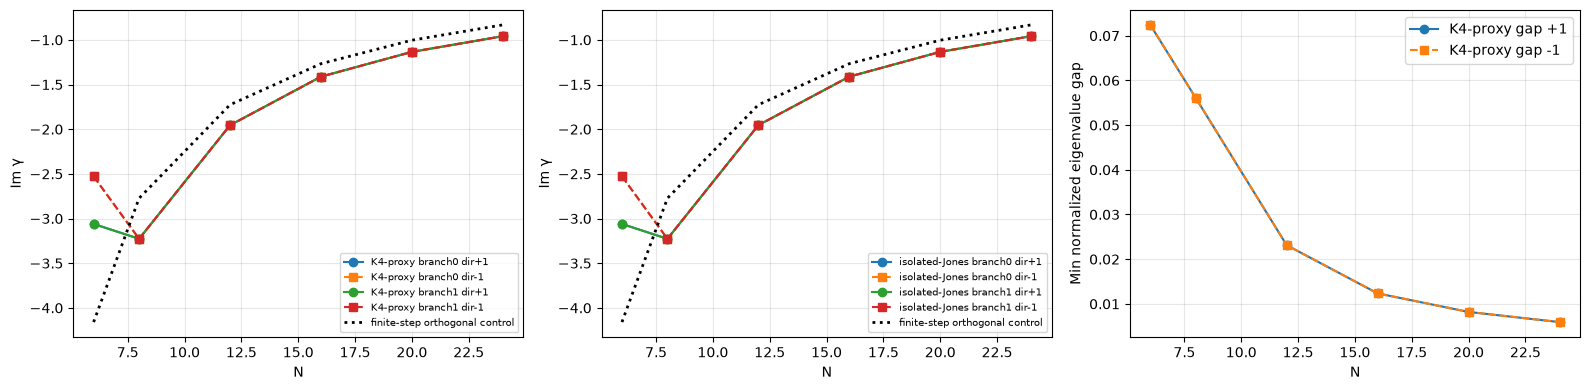

In [17]:
if RUN_PERIODIC:
    fig,axs=plt.subplots(1,3,figsize=(16,4))
    for b in (0,1):
        for d,sty in [(+1,'o-'),(-1,'s--')]:
            valid=[n for n in N_SWEEP if (n,d) in transport]
            axs[0].plot(valid,[transport[(n,d)]['gamma'][b].imag for n in valid],
                       sty,label=f'K4-proxy branch{b} dir{d:+d}')
            axs[1].plot(N_SWEEP,[slice_controls[(n,d)]['gamma'][b].imag for n in N_SWEEP],
                        sty,label=f'isolated-Jones branch{b} dir{d:+d}')
    control_curve=[orthogonal_projection_baseline(n) for n in N_SWEEP]
    for ax in axs[:2]:
        ax.plot(N_SWEEP,control_curve,'k:',lw=2,label='finite-step orthogonal control')
        ax.set(xlabel='N',ylabel='Im γ');ax.legend(fontsize=7);ax.grid(alpha=.3)
    for d,sty in [(+1,'o-'),(-1,'s--')]:
        valid=[n for n in N_SWEEP if (n,d) in transport]
        axs[2].plot(valid,[np.min(transport[(n,d)]['normalized_gap']) for n in valid],
                    sty,label=f'K4-proxy gap {d:+d}')
    axs[2].set(xlabel='N',ylabel='Min normalized eigenvalue gap');axs[2].grid(alpha=.3);axs[2].legend()
    plt.tight_layout();plt.show()
    if len(transport)<2*len(N_SWEEP):
        print('WARNING: some generator proxies failed; theoretical phase incomplete.')

## 13 · **NEW:** Physical phase witnesses versus modeled geometric phase

Compare coherent Maxwell output with the empty-device complex reference and orientation-reversed control. The phase of a coherent analyzer channel is not the geometric eigenphase. A one-pole resonance fit is only phenomenological; its background and pole **amplitudes** sum and the resulting phases do not. A full dynamical/geometric/resonant additive split is not uniquely defined in a strongly coupled layered Maxwell problem.

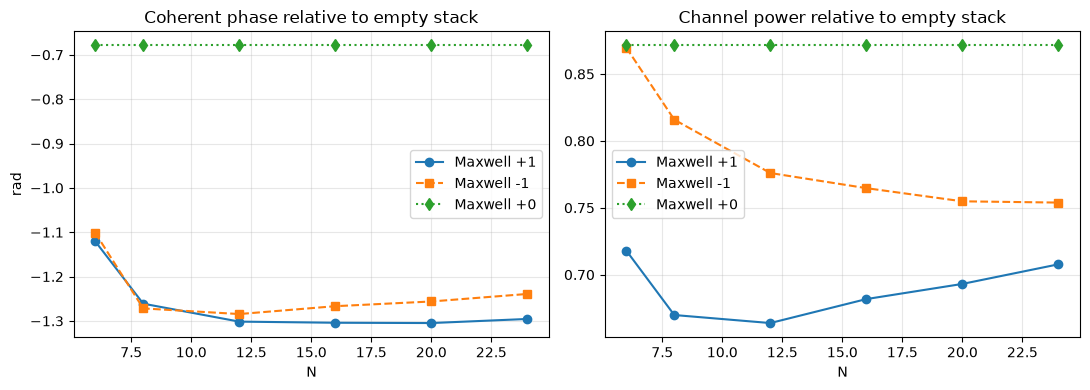

N= 6 measured amplitude f/r=0.908608, odd analyzer phase=-0.00958 rad; modeled Wilson orientation-odd branches=[-0.    -0.2661j -3.1416-0.2661j]
N= 8 measured amplitude f/r=0.906104, odd analyzer phase=+0.00534 rad; modeled Wilson orientation-odd branches=[-0.-0.0006j  0.+0.0006j]
N=12 measured amplitude f/r=0.924918, odd analyzer phase=-0.00854 rad; modeled Wilson orientation-odd branches=[ 0.-0.0001j -0.+0.0001j]
N=16 measured amplitude f/r=0.944229, odd analyzer phase=-0.01867 rad; modeled Wilson orientation-odd branches=[ 0.-0.j -0.+0.j]
N=20 measured amplitude f/r=0.958227, odd analyzer phase=-0.02432 rad; modeled Wilson orientation-odd branches=[-0.-0.j  0.+0.j]
N=24 measured amplitude f/r=0.968908, odd analyzer phase=-0.02819 rad; modeled Wilson orientation-odd branches=[ 0.-0.j -0.+0.j]


In [18]:
if RUN_PERIODIC and bare is not None:
    ref=projected_channel(bare['T'],INPUT,ANALYZER)
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    for d,sty in [(+1,'o-'),(-1,'s--'),(0,'d:')]:
        coeffs=[projected_channel(periodic[(n,d)]['T'],INPUT,ANALYZER)/ref for n in N_SWEEP]
        axs[0].plot(N_SWEEP,np.unwrap(np.angle(coeffs)),sty,label=f'Maxwell {d:+d}')
        axs[1].plot(N_SWEEP,np.abs(coeffs)**2,sty,label=f'Maxwell {d:+d}')
    axs[0].set(title='Coherent phase relative to empty stack',ylabel='rad')
    axs[1].set(title='Channel power relative to empty stack')
    for ax in axs:ax.set(xlabel='N');ax.grid(alpha=.3);ax.legend()
    plt.tight_layout();plt.show()
    for n in N_SWEEP:
        f=projected_channel(periodic[(n,+1)]['T'],INPUT,ANALYZER)
        r=projected_channel(periodic[(n,-1)]['T'],INPUT,ANALYZER)
        amp_ratio=np.abs(f)/max(np.abs(r),1e-12)
        phase_odd=.5*np.angle(f/r)
        wilson=(np.round(.5*(transport[(n,+1)]['gamma']-
                                 transport[(n,-1)]['gamma']),4)
                if (n,+1) in transport and (n,-1) in transport else 'invalid')
        print(f'N={n:2} measured amplitude f/r={amp_ratio:.6f}, '
              f'odd analyzer phase={phase_odd:+.5f} rad; '
              f'modeled Wilson orientation-odd branches={wilson}')

## 14 · **NEW:** Save explicit epistemic labels and all local modes

Export both the old isolated-Jones control and the two-way transfer-generator proxy separately. A missing or ill-conditioned forward subspace is a **negative result**, not permission to replace it silently with the isolated-slice model. The raw Maxwell stack S remains the primary experimental result.

In [19]:
if RUN_PERIODIC:
    folder=OUT/'transfer_generator_proxy';folder.mkdir(exist_ok=True)
    for (N,d),t in transport.items():
        local=generator_proxies[(N,d)]
        np.savez_compressed(folder/f'K4_N{N:03}_dir{d:+d}.npz',
            local_K4=np.array([x['K4'] for x in local]),
            local_transfer=np.array([x['transfer'] for x in local]),
            eta=np.array([x['eta'] for x in local]),
            forward_lambda=np.array([x['forward_lambda'] for x in local]),
            modal_flux=np.array([x['flux'] for x in local]),
            right=t['R'],left=t['L'],gamma=t['gamma'],
            links=t['links'],gap=t['normalized_gap'])
    for (N,d),t in slice_controls.items():
        np.savez_compressed(folder/f'isolated_Jones_CONTROL_N{N:03}_dir{d:+d}.npz',
            eta=t['eta'],gamma=t['gamma'],R=t['R'],L=t['L'],links=t['links'])
    (folder/'failed_generator_cases.json').write_text(json.dumps(
        {f'N{k[0]}_dir{k[1]}':v for k,v in generator_failures.items()},indent=2))
    print('Saved physically qualified generator-proxy and isolated-control artifacts')

Saved physically qualified generator-proxy and isolated-control artifacts


## 15 · Optional spatially varying **finite** arrays

This is a separate finite-domain 3D Meep experiment, with PML in x/y/z. Each site carries its own orientation offset, not the same rotated motif everywhere. This run is gated because resolving H/N at ≥4 cells per slice and converging radiated power can be exceptionally expensive.

In [20]:
finite_spatial={}
if RUN_SPATIAL_FINITE:
    winding=Pattern(nx=FINITE_OPT.nx,ny=FINITE_OPT.ny,qx=1,qy=0)
    for N in FINITE_N:
        for direction in (+1,-1,0):
            response=finite_meep_forward(p,rules,geom,cfg,N,
                opts=FINITE_OPT,height_um=H,wavelength_um=LAMBDA0,
                direction=direction,pattern=winding,save_fields=False)
            finite_spatial[(N,direction)]=response
            print('finite winding',N,direction,response['T_relative_bare'])
    np.savez_compressed(OUT/'finite_spatial_winding.npz',
       index=np.asarray(sorted(finite_spatial),int),
       transmission=np.asarray([finite_spatial[k]['T_relative_bare']
                                for k in sorted(finite_spatial)]))
